# PjBL2 – Validação cruzada 5-fold na batata (MobileNetV2)

**Por que este notebook?** A Aula 03 (p. 25–26) apresenta dois protocolos experimentais:
- o ***holdout*** (uma única divisão treino × teste/validação);
- a **validação cruzada (k-fold)**, que "reduz chances de *overfitting*" e "melhora a reamostragem dos modelos".

O resultado principal do PjBL2 usa *holdout* 70/15/15 (`batata.ipynb`). Ele mostra o desempenho em **uma** divisão, mas não diz quanto esse número mudaria com outra divisão. A validação cruzada responde a essa pergunta: **o modelo é estável entre divisões diferentes?**

**Protocolo:**
1. **O teste original (15%, 323 imagens) fica de fora e intocado.** Ele continua sendo o *holdout* final, usado uma única vez em `batata.ipynb`. Este notebook nem o carrega para treino ou avaliação; só confere que nenhuma imagem dele entra nos folds.
2. **Junção de treino e validação:** os 85% restantes (1.506 + 323 = 1.829 imagens) formam um único conjunto.
3. **Divisão em 5 folds:** esse conjunto é dividido em **5 partes estratificadas** (mesma proporção de classes em cada uma), com semente 42. Imagens idênticas (mesmo MD5) ficam sempre no mesmo fold, como em `scripts/preparar_dados.py`.
4. **5 rodadas de treino:** em cada uma, 4 folds treinam e o fold restante é o **fold de validação**. A receita é a mesma do *holdout*:
   - MobileNetV2 da ImageNet treinada em 2 etapas (6 épocas só da cabeça + 6 épocas de ajuste fino dos últimos 5 blocos);
   - aumento de dados **só nos folds de treino**;
   - pesos de classe calculados em cada fold de treino;
   - *BatchNorm* congelado;
   - **melhor época escolhida pelo F1 macro no fold de validação**.
5. **Métricas:** por fold e média ± desvio-padrão de acurácia, precisão, revocação e F1 macro, e de especificidade macro (VN/(VN+FP), Aula 03, p. 29).

**Observação honesta:** o mesmo fold escolhe a melhor época e mede as métricas, o que deixa o número **levemente otimista**. Por isso também registramos as métricas da **última época (12)**, que não envolvem nenhuma escolha.

## 0. Configuração e reprodutibilidade

In [1]:
import hashlib, json, os, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support

INICIO = time.time()
SEMENTE = 42
K = 5
def semear(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
semear(SEMENTE)
torch.set_num_threads(os.cpu_count() or 4)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PLANTA = "batata"
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "preparar_dados.py").exists())
SPLITS = RAIZ / "dados" / "splits" / PLANTA
MODELOS = RAIZ / "modelos"
CLASSES = ["Potato___Early_blight", "Potato___Late_blight", "Potato___healthy"]
IDX = {c: i for i, c in enumerate(CLASSES)}
curto = lambda c: c.split("___")[1].replace("_", " ").strip()
print("Dispositivo:", DISPOSITIVO, "| threads:", torch.get_num_threads(), "| torch", torch.__version__)

Dispositivo: cpu | threads: 8 | torch 2.14.1+cpu


## 1. Conjunto da validação cruzada: treino + validação (85%); teste excluído
Juntamos `treino.csv` e `validacao.csv`. O `teste.csv` só é lido para **conferir** que nenhuma imagem dele aparece no conjunto.
Os folds são sorteados por **grupo de MD5**, para que imagens idênticas nunca fiquem uma no treino e outra no fold de validação.

In [2]:
pool = pd.concat([pd.read_csv(SPLITS / "treino.csv"), pd.read_csv(SPLITS / "validacao.csv")], ignore_index=True)
caminhos_teste = set(pd.read_csv(SPLITS / "teste.csv").caminho)
assert not (set(pool.caminho) & caminhos_teste), "Imagem do teste no conjunto da validação cruzada!"
pool["md5"] = [hashlib.md5((RAIZ / c).read_bytes()).hexdigest() for c in pool.caminho]
grupos = pool.drop_duplicates("md5")[["md5", "classe"]].reset_index(drop=True)
print(f"Imagens no conjunto: {len(pool)} | únicas (MD5): {len(grupos)} | teste excluído: {len(caminhos_teste)}")

skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEMENTE)
grupos["fold"] = -1
for f, (_, idx_val) in enumerate(skf.split(grupos, grupos.classe)):
    grupos.loc[idx_val, "fold"] = f
pool = pool.merge(grupos[["md5", "fold"]], on="md5")
tab = pd.crosstab(pool.classe, pool.fold, margins=True, margins_name="total")
tab.columns = [f"fold {c+1}" if c != "total" else c for c in tab.columns]
tab

Imagens no conjunto: 1829 | únicas (MD5): 1829 | teste excluído: 323


,fold 1,fold 2,fold 3,fold 4,fold 5,total
classe,,,,,,
Potato___Early_blight,170,170,170,170,170,850
Potato___Late_blight,170,170,170,170,170,850
Potato___healthy,26,26,26,26,25,129
total,366,366,366,366,365,1829


## 2. Pré-processamento, aumento de dados e modelo
Tudo é idêntico ao `batata.ipynb`:
- **Avaliação:** redimensionamento para 224×224 igual ao do app, seguido da normalização da ImageNet.
- **Treino:** aumento de dados (recorte e zoom, espelhamentos, rotação de ±20°, brilho e contraste), aplicado só nas imagens do fold de treino.
- **Modelo:** MobileNetV2 com cabeça `Dropout(0,2) + Linear(1280 → 3)`.

In [3]:
TAM, LOTE = 224, 32
MEDIA, DESVIO = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class RedimensionarComoApp:
    def __call__(self, img): return img.resize((TAM, TAM))

tf_avaliacao = transforms.Compose([RedimensionarComoApp(), transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIO)])
tf_treino = transforms.Compose([
    transforms.RandomResizedCrop(TAM, scale=(0.8, 1.0)), transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20), transforms.ColorJitter(brightness=0.25, contrast=0.2, saturation=0.15),
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIO)])

class FolhasDataset(Dataset):
    def __init__(self, df, transform):
        self.caminhos = [RAIZ / c for c in df.caminho]; self.rotulos = [IDX[c] for c in df.classe]; self.transform = transform
    def __len__(self): return len(self.caminhos)
    def __getitem__(self, i): return self.transform(Image.open(self.caminhos[i]).convert("RGB")), self.rotulos[i]

HP = {"lote": LOTE, "epocas_etapa1": 6, "lr_etapa1": 1e-3, "epocas_etapa2": 6, "lr_etapa2": 1e-4,
      "blocos_descongelados_etapa2": 5, "otimizador": "Adam", "weight_decay": 1e-4, "dropout": 0.2,
      "tamanho_entrada": TAM, "semente": SEMENTE, "pesos_classe": "inverso da frequência (por fold de treino)"}

def modo_treino(m):
    m.train()
    for camada in m.modules():
        if isinstance(camada, nn.BatchNorm2d): camada.eval()

@torch.no_grad()
def prever(m, dl):
    m.eval(); probs, y = [], []
    for x, rot in dl:
        probs.append(torch.softmax(m(x.to(DISPOSITIVO)), 1).cpu()); y.append(rot)
    return torch.cat(probs).numpy(), torch.cat(y).numpy()

def metricas(y, pred):
    mc = confusion_matrix(y, pred, labels=range(len(CLASSES)))
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=range(len(CLASSES)), zero_division=0)
    vp = np.diag(mc); fp = mc.sum(0) - vp; fn = mc.sum(1) - vp; vn = mc.sum() - vp - fp - fn
    esp = vn / (vn + fp)                                   # especificidade um-contra-todos (Aula 03, p. 29)
    return {"acuracia": float(accuracy_score(y, pred)), "precisao_macro": float(p.mean()), "revocacao_macro": float(r.mean()),
            "f1_macro": float(f.mean()), "especificidade_macro": float(esp.mean()),
            "f1_por_classe": {c: float(v) for c, v in zip(CLASSES, f)},
            "especificidade_por_classe": {c: float(v) for c, v in zip(CLASSES, esp)},
            "matriz_confusao": mc.tolist()}

## 3. Treino dos 5 folds
Cada fold começa do zero, com os pesos da ImageNet. A cada época medimos o F1 macro no fold de validação e guardamos os melhores pesos.
Isso equivale à parada antecipada da Aula 04, p. 40–42.

In [4]:
resultados = []
for f in range(K):
    t_fold = time.time(); semear(SEMENTE + f)
    tr, va = pool[pool.fold != f], pool[pool.fold == f]
    g = torch.Generator().manual_seed(SEMENTE + f)
    dl_tr = DataLoader(FolhasDataset(tr, tf_treino), batch_size=LOTE, shuffle=True, num_workers=4, generator=g)
    dl_va = DataLoader(FolhasDataset(va, tf_avaliacao), batch_size=64, num_workers=4)

    modelo = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    modelo.classifier = nn.Sequential(nn.Dropout(HP["dropout"]), nn.Linear(modelo.last_channel, len(CLASSES)))
    modelo = modelo.to(DISPOSITIVO)
    freq = tr.classe.value_counts().reindex(CLASSES).values.astype(float)
    criterio = nn.CrossEntropyLoss(weight=torch.tensor(freq.sum() / (len(CLASSES) * freq), dtype=torch.float32, device=DISPOSITIVO))

    historico, melhor = [], {"f1": -1, "epoca": None, "estado": None}
    def treinar(otim, epocas, etapa):
        for _ in range(epocas):
            modo_treino(modelo); perda_t, n = 0.0, 0
            for x, rot in dl_tr:
                x, rot = x.to(DISPOSITIVO), rot.to(DISPOSITIVO)
                otim.zero_grad(); perda = criterio(modelo(x), rot); perda.backward(); otim.step()
                perda_t += perda.item() * len(rot); n += len(rot)
            p_va, y_va = prever(modelo, dl_va)
            f1v = f1_score(y_va, p_va.argmax(1), average="macro")
            historico.append({"etapa": etapa, "epoca": len(historico) + 1, "perda_treino": perda_t / n,
                              "acc_val": float(accuracy_score(y_va, p_va.argmax(1))), "f1_macro_val": float(f1v)})
            if f1v > melhor["f1"]:
                melhor.update(f1=f1v, epoca=len(historico), estado={k: v.detach().clone() for k, v in modelo.state_dict().items()})

    for p in modelo.features.parameters(): p.requires_grad = False
    treinar(torch.optim.Adam(modelo.classifier.parameters(), lr=HP["lr_etapa1"], weight_decay=HP["weight_decay"]), HP["epocas_etapa1"], 1)
    for p in modelo.features[-HP["blocos_descongelados_etapa2"]:].parameters(): p.requires_grad = True
    treinar(torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=HP["lr_etapa2"],
                             weight_decay=HP["weight_decay"]), HP["epocas_etapa2"], 2)

    p_ult, y_va = prever(modelo, dl_va)                    # última época (sem escolha)
    modelo.load_state_dict(melhor["estado"])
    p_mel, _ = prever(modelo, dl_va)                       # melhor época no fold de validação
    r = {"fold": f + 1, "n_treino": len(tr), "n_validacao": len(va), "melhor_epoca": melhor["epoca"],
         "melhor_epoca_metricas": metricas(y_va, p_mel.argmax(1)), "ultima_epoca_metricas": metricas(y_va, p_ult.argmax(1)),
         "historico": historico, "tempo_min": round((time.time() - t_fold) / 60, 1)}
    resultados.append(r)
    m = r["melhor_epoca_metricas"]
    print(f"fold {f+1}: treino {len(tr)} | val {len(va)} | melhor época {melhor['epoca']:2d} | acc {m['acuracia']:.4f} "
          f"F1 {m['f1_macro']:.4f} esp {m['especificidade_macro']:.4f} | última época F1 {r['ultima_epoca_metricas']['f1_macro']:.4f} "
          f"| {r['tempo_min']} min", flush=True)

fold 1: treino 1463 | val 366 | melhor época  8 | acc 0.9918 F1 0.9886 esp 0.9949 | última época F1 0.9553 | 4.7 min


fold 2: treino 1463 | val 366 | melhor época 12 | acc 0.9945 F1 0.9908 esp 0.9973 | última época F1 0.9908 | 8.4 min


fold 3: treino 1463 | val 366 | melhor época  9 | acc 0.9945 F1 0.9961 esp 0.9966 | última época F1 0.9789 | 4.7 min


fold 4: treino 1463 | val 366 | melhor época 12 | acc 1.0000 F1 1.0000 esp 1.0000 | última época F1 1.0000 | 7.0 min


fold 5: treino 1464 | val 365 | melhor época 12 | acc 0.9973 F1 0.9980 esp 0.9983 | última época F1 0.9980 | 4.3 min


## 4. Resultados por fold e média ± desvio-padrão

In [5]:
NOMES = {"acuracia": "Acurácia", "precisao_macro": "Precisão macro", "revocacao_macro": "Revocação macro",
         "f1_macro": "F1 macro", "especificidade_macro": "Especificidade macro"}
def tabela(chave):
    t = pd.DataFrame([{"fold": r["fold"], "melhor época": r["melhor_epoca"], **{NOMES[k]: r[chave][k] for k in NOMES}}
                      for r in resultados]).set_index("fold")
    t.loc["média"] = t.mean(); t.loc["desvio-padrão"] = t.iloc[:K].std(ddof=1)
    return t
tab_melhor, tab_ultima = tabela("melhor_epoca_metricas"), tabela("ultima_epoca_metricas")
print("Melhor época escolhida no fold de validação:"); display(tab_melhor.round(4))
print("Última época (12), sem escolha de época:"); display(tab_ultima.round(4))

Melhor época escolhida no fold de validação:


,melhor época,Acurácia,Precisão macro,Revocação macro,F1 macro,Especificidade macro
fold,,,,,,
1,8.0000,0.9918,0.9942,0.9833,0.9886,0.9949
2,12.0000,0.9945,0.9857,0.9961,0.9908,0.9973
3,9.0000,0.9945,0.9961,0.9961,0.9961,0.9966
4,12.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,12.0000,0.9973,0.9981,0.9980,0.9980,0.9983
média,10.6000,0.9956,0.9948,0.9947,0.9947,0.9974
desvio-padrão,1.9494,0.0031,0.0055,0.0066,0.0049,0.0019


Última época (12), sem escolha de época:


,melhor época,Acurácia,Precisão macro,Revocação macro,F1 macro,Especificidade macro
fold,,,,,,
1,8.0000,0.9590,0.9432,0.9706,0.9553,0.9767
2,12.0000,0.9945,0.9857,0.9961,0.9908,0.9973
3,9.0000,0.9918,0.9655,0.9941,0.9789,0.9971
4,12.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,12.0000,0.9973,0.9981,0.9980,0.9980,0.9983
média,10.6000,0.9885,0.9785,0.9918,0.9846,0.9939
desvio-padrão,1.9494,0.0168,0.0240,0.0120,0.0184,0.0097


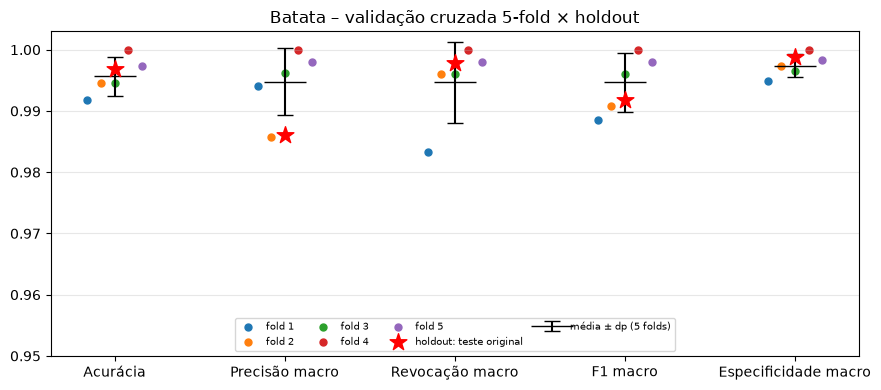

In [6]:
holdout = json.load(open(MODELOS / "metricas_batata.json", encoding="utf-8"))
ref = {"acuracia": holdout["teste"]["acuracia"], "precisao_macro": holdout["teste"]["precisao_macro"],
       "revocacao_macro": holdout["teste"]["revocacao_macro"], "f1_macro": holdout["teste"]["f1_macro"],
       "especificidade_macro": holdout["teste"].get("especificidade_macro")}

fig, a = plt.subplots(figsize=(9, 4))
x = np.arange(len(NOMES))
for i, r in enumerate(resultados):
    a.scatter(x + (i - 2) * 0.08, [r["melhor_epoca_metricas"][k] for k in NOMES], s=25, label=f"fold {r['fold']}")
med = tab_melhor.loc["média", list(NOMES.values())].values; dp = tab_melhor.loc["desvio-padrão", list(NOMES.values())].values
a.errorbar(x, med, yerr=dp, fmt="_", color="black", markersize=30, capsize=6, label="média ± dp (5 folds)")
a.scatter(x, [ref[k] for k in NOMES], marker="*", s=160, color="red", zorder=5, label="holdout: teste original")
a.set_xticks(x); a.set_xticklabels(NOMES.values()); a.set_ylim(min(0.95, float(np.min(med - dp)) - 0.01), 1.003)
a.set_title("Batata – validação cruzada 5-fold × holdout"); a.grid(alpha=0.3, axis="y"); a.legend(fontsize=7, ncol=4, loc="lower center")
plt.tight_layout(); plt.savefig(MODELOS / "kfold_batata.png", dpi=130); plt.show()

## 5. Matriz de confusão somada dos 5 folds (cada imagem avaliada uma vez, pelo modelo que não a viu no treino)

In [7]:
mc_total = np.sum([r["melhor_epoca_metricas"]["matriz_confusao"] for r in resultados], axis=0)
print(pd.DataFrame(mc_total, index=[f"real: {curto(c)}" for c in CLASSES], columns=[f"prev: {curto(c)}" for c in CLASSES]))
print(f"Erros: {int(mc_total.sum() - np.trace(mc_total))} de {int(mc_total.sum())} imagens")

                    prev: Early blight  prev: Late blight  prev: healthy
real: Early blight                 848                  2              0
real: Late blight                    4                845              1
real: healthy                        0                  1            128
Erros: 8 de 1829 imagens


## 6. Salvando `modelos/kfold_batata.json`

In [8]:
resumo = lambda chave: {k: {"media": float(np.mean([r[chave][k] for r in resultados])),
                            "desvio_padrao": float(np.std([r[chave][k] for r in resultados], ddof=1))} for k in NOMES}
saida = {
    "planta": PLANTA, "protocolo": {
        "tipo": "validação cruzada estratificada k-fold (Aula 03, p. 26)", "k": K, "semente": SEMENTE,
        "conjunto": "treino + validação da divisão 70/15/15 (85%)", "n_imagens": len(pool),
        "teste_original": f"excluído e intocado ({len(caminhos_teste)} imagens; continua sendo o holdout final)",
        "agrupamento": "imagens com o mesmo MD5 ficam no mesmo fold",
        "escolha_de_epoca": "melhor F1 macro no fold de validação (também registradas as métricas da última época)",
        "observacao": "o fold que escolhe a época também mede as métricas: estimativa levemente otimista"},
    "hiperparametros": HP, "classes": CLASSES,
    "media_dp_melhor_epoca": resumo("melhor_epoca_metricas"), "media_dp_ultima_epoca": resumo("ultima_epoca_metricas"),
    "matriz_confusao_somada": {"valores": mc_total.tolist(), "linhas": "real", "colunas": "prevista"},
    "holdout_teste_referencia": ref, "folds": resultados,
    "ambiente": {"plataforma": "cpu" if DISPOSITIVO.type == "cpu" else "gpu", "torch": torch.__version__,
                 "threads": torch.get_num_threads(), "tempo_total_min": round((time.time() - INICIO) / 60, 1)},
    "executado_em": pd.Timestamp.now(tz="UTC").isoformat(),
}
with open(MODELOS / "kfold_batata.json", "w", encoding="utf-8") as fh:
    json.dump(saida, fh, ensure_ascii=False, indent=2)
print(json.dumps({"melhor_epoca": saida["media_dp_melhor_epoca"], "tempo_total_min": saida["ambiente"]["tempo_total_min"]},
                 ensure_ascii=False, indent=1))

{
 "melhor_epoca": {
  "acuracia": {
   "media": 0.9956269181824986,
   "desvio_padrao": 0.0031142502509408955
  },
  "precisao_macro": {
   "media": 0.994803978872574,
   "desvio_padrao": 0.0055386811016457675
  },
  "revocacao_macro": {
   "media": 0.9946907993966818,
   "desvio_padrao": 0.006594719707907333
  },
  "f1_macro": {
   "media": 0.9946897999560456,
   "desvio_padrao": 0.004854136153487947
  },
  "especificidade_macro": {
   "media": 0.9974212249002165,
   "desvio_padrao": 0.001901306954465997
  }
 },
 "tempo_total_min": 29.1
}


## 7. Como interpretar (para a defesa)
- **Estabilidade:** o desvio-padrão entre os folds mostra quanto a métrica muda quando a divisão muda. Um desvio pequeno indica que o resultado do *holdout* não foi "sorte" de uma divisão favorável.
- **Comparação com o *holdout*:** a estrela vermelha no gráfico é o resultado no teste original, que é independente e foi usado uma vez. Se ela cai dentro da faixa média ± desvio dos folds, as duas estimativas concordam.
- **Por que não substituir o *holdout*?** A validação cruzada estima a **receita** de treino (5 modelos diferentes). O modelo entregue (`batata.onnx`) é o do *holdout*, avaliado no teste original. Os dois protocolos se complementam.
- **Limitação:** as imagens são do PlantVillage, fotografadas em laboratório. A estabilidade entre folds não garante o mesmo desempenho em fotos de campo.